# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 24)
Train: 947 | Val: 229 | Test: 567


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 3.42e-04 | train loss 1.1244 acc 0.416 | val loss 1.0784 acc 0.559 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 3.42e-04 | train loss 1.0436 acc 0.502 | val loss 1.0330 acc 0.590 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 3.42e-04 | train loss 1.0082 acc 0.551 | val loss 1.0134 acc 0.590 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 3.42e-04 | train loss 0.9417 acc 0.629 | val loss 1.1862 acc 0.441


...

[ResNet-18 (scratch)] Epoch  28/100 | LR: 3.42e-04 | train loss 0.5924 acc 0.743 | val loss 0.9563 acc 0.607


[ResNet-18 (scratch)] Epoch  29/100 | LR: 3.42e-05 | train loss 0.6114 acc 0.754 | val loss 0.9307 acc 0.664


[ResNet-18 (scratch)] Epoch  30/100 | LR: 3.42e-05 | train loss 0.4548 acc 0.820 | val loss 0.7619 acc 0.764


[ResNet-18 (scratch)] Epoch  31/100 | LR: 3.42e-05 | train loss 0.3977 acc 0.851 | val loss 0.7638 acc 0.742


[ResNet-18 (scratch)] Epoch  32/100 | LR: 3.42e-05 | train loss 0.3968 acc 0.835 | val loss 0.7761 acc 0.742

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 32.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.7090)


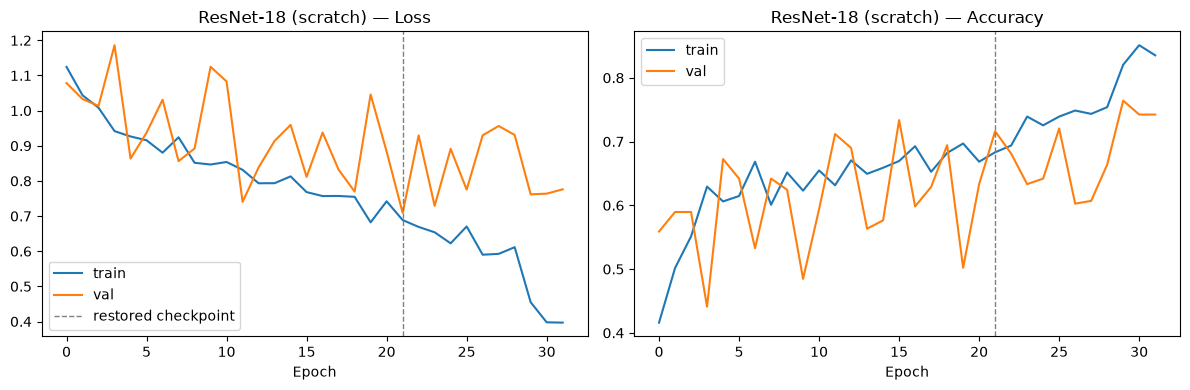

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.764


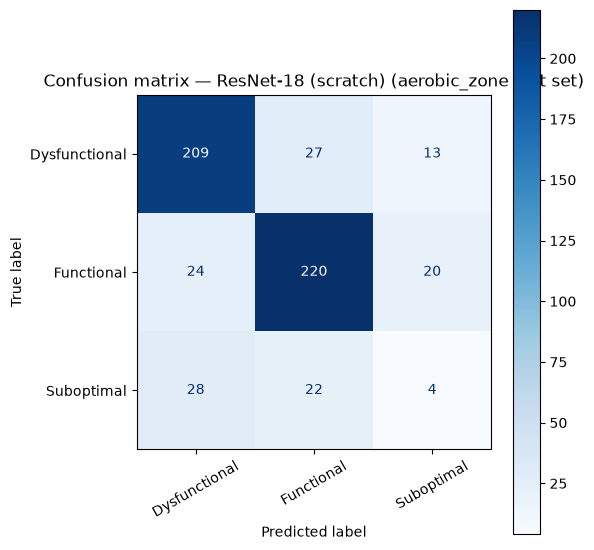

               precision    recall  f1-score   support

Dysfunctional      0.801     0.839     0.820       249
   Functional      0.818     0.833     0.826       264
   Suboptimal      0.108     0.074     0.088        54

     accuracy                          0.764       567
    macro avg      0.576     0.582     0.578       567
 weighted avg      0.743     0.764     0.753       567



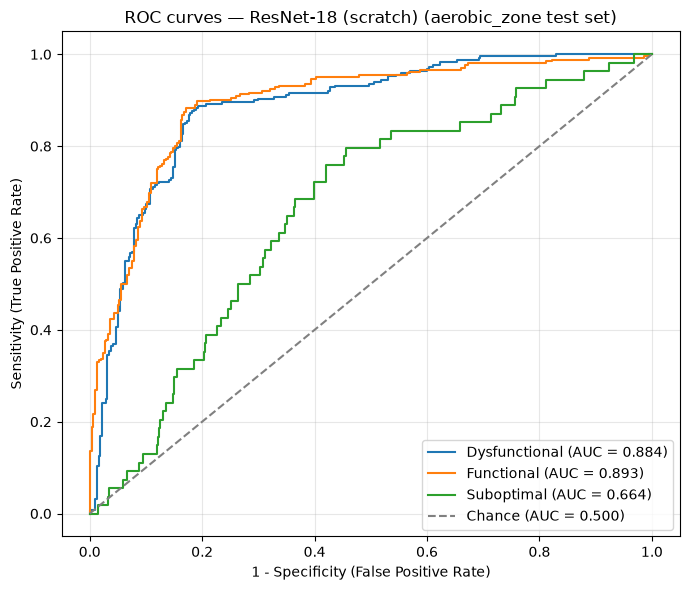

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.884
  Functional     : 0.893
  Suboptimal     : 0.664

Mean AUC (over 3/3 classes with test examples): 0.814


(np.float64(0.763668430335097),
 {'Dysfunctional': 0.8838498648682782,
  'Functional': 0.8929142914291428,
  'Suboptimal': 0.6643202656847881})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_noaug/aerobic_zone_resnet18_scratch_chronological.pt
